# 04a. Analyse exploratoire avant la modélisation

Sentinelle Scolaire, défi 1.

Avant d'entraîner un modèle, on regarde la cible et les variables candidates, pour l'ensemble des élèves (base apurée, 47 provinces × 9 années) et par sexe (base par sexe, 846 lignes) :

1. **la cible** : l'abandon du primaire de t à t+1, valeur `abandon_primaire_precedent` de l'année t+1 ;
2. **sa variance** : part due aux écarts entre provinces, part due aux changements dans le temps, et erreur des prévisions de référence ;
3. **la qualité** de chaque variable : part de valeurs observées, variable constante dans le temps ;
4. **la colinéarité** entre variables : groupes de corrélation de rang |ρ| ≥ 0,85, facteur d'inflation de la variance (VIF) ;
5. **le lien avec la cible** : global, entre provinces, dans le temps, sachant l'abandon de l'année t ; les **ruptures de scolarisation** (effectifs qui varient de plus de 30 % entre t et t+1) sont écartées de ces analyses : l'abandon apparent y mesure la fermeture d'écoles, pas le décrochage ;
6. **la décision** pour chaque variable, avec son motif.

**Règle contre la fuite d'information.** Qualité et colinéarité n'utilisent pas la cible : elles portent sur toutes les années. Variance et liens utilisent la cible : ils portent sur les seules années d'apprentissage, avant l'année gardée pour le test final (2023-2024 pour l'ensemble, 2022-2023 par sexe, faute d'effectifs par sexe fiables en 2024-2025). Seules les cibles observées sont utilisées.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentinelle.analyse import ENTREE, executer_exploration
from sentinelle.analyse import exploration

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})
SOURCE = "Source : annuaires DGESS, base apurée du défi 1. Calculs des auteurs."
FILLES, GARCONS, NEUTRE = "#b5446e", "#2f6f9f", "#8a8984"

In [2]:
tables = executer_exploration()
jeux = exploration.charger(ENTREE)

## 1. La cible

L'abandon mesuré est un abandon *apparent* : élèves de t qui ne sont ni promus ni redoublants en t+1. Il inclut les départs nets vers d'autres provinces. Les années de crise (fermetures d'écoles, déplacements) donnent des valeurs très élevées dans certaines provinces : jusqu'à 99 % en 2021-2022.

In [3]:
tables["cible_par_annee_ensemble"]

,annee_scolaire,cibles_observees,ruptures,moyenne_hors_ruptures,moyenne,mediane,p10,p90,minimum,maximum,negatives,superieures_a_30
0,2016-2017,43,0,7.09,7.09,6.18,3.77,12.73,2.68,20.44,0,0
1,2017-2018,43,3,8.61,11.69,8.43,5.04,19.41,1.72,57.78,0,3
2,2018-2019,43,3,12.29,15.00,8.24,5.59,33.25,2.99,53.66,0,6
3,2019-2020,43,1,9.07,10.51,8.35,2.22,14.80,-2.68,71.02,2,4
4,2020-2021,43,5,13.09,18.77,10.50,7.06,37.70,4.60,97.60,0,7
5,2021-2022,40,8,17.93,27.19,15.31,8.78,55.93,2.87,99.29,0,15
6,2022-2023,34,2,9.56,8.99,7.50,3.12,19.30,-4.48,26.85,2,0
7,2023-2024,42,2,8.87,8.49,7.62,1.60,17.10,-1.37,34.35,3,1


Les ruptures de scolarisation : 8 % des cibles, mais l'essentiel de leur variance.

In [4]:
tables["ruptures_ensemble"]

,province_nom,region_nom,annee_scolaire,cible,abandon_primaire_precedent,evolution_effectifs_suivante
37,Koulpelogo,Nakambe,2021-2022,50.74,20.79,-0.416
39,Koulpelogo,Nakambe,2023-2024,3.31,22.90,0.342
61,Namentenga,Koulse,2021-2022,55.25,22.23,-0.482
156,Loroum,Yaadga,2020-2021,97.60,32.00,-0.976
182,Zondoma,Yaadga,2022-2023,-4.48,38.36,0.310
244,Gnagna,Sirba,2020-2021,38.63,11.18,-0.312
245,Gnagna,Sirba,2021-2022,64.75,38.63,-0.630
249,Komandjari,Sirba,2017-2018,53.17,13.98,-0.458
250,Komandjari,Sirba,2018-2019,50.57,53.17,-0.440
293,Kossin,Sourou,2021-2022,42.84,33.69,-0.337


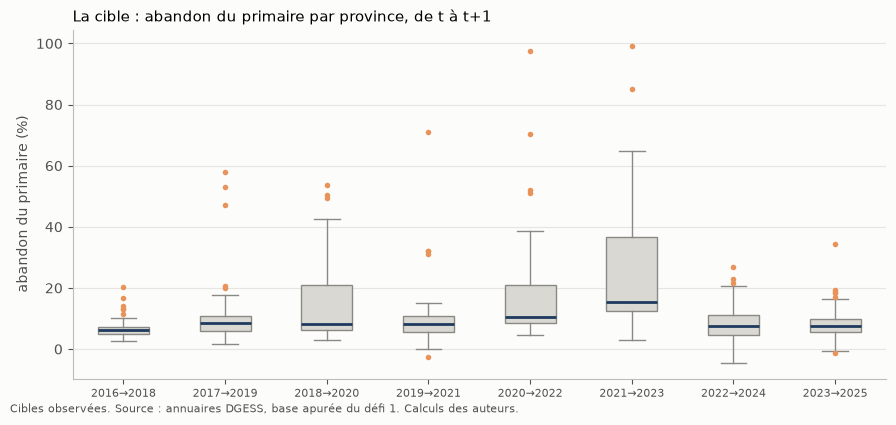

In [5]:
t = jeux["ensemble"]["table"]
obs = t[t["cible_observee_suivante"]]
annees = sorted(obs["annee_scolaire"].unique())
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.boxplot([obs.loc[obs["annee_scolaire"] == a, "cible"] for a in annees], widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#d9d8d3", edgecolor="#8a8984"), medianprops=dict(color="#1f3a5f", lw=2),
           whiskerprops=dict(color="#8a8984"), capprops=dict(color="#8a8984"),
           flierprops=dict(marker="o", markersize=4, markerfacecolor="#e8935a", markeredgecolor="none"))
ax.set_xticks(range(1, len(annees) + 1), [f"{a[:4]}→{int(a[:4]) + 2}" for a in annees], fontsize=8)
ax.set_ylabel("abandon du primaire (%)")
ax.grid(axis="y", color="#e6e5e0")
ax.set_title("La cible : abandon du primaire par province, de t à t+1", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Cibles observées. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

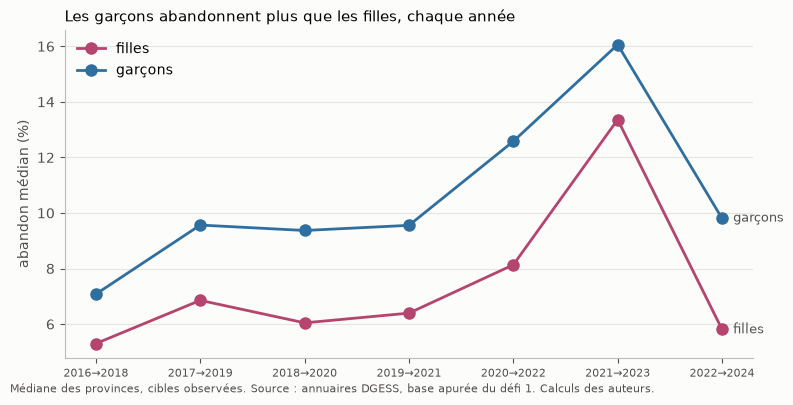

In [6]:
ts = jeux["sexe"]["table"]
obs_s = ts[ts["cible_observee_suivante"]]
med = obs_s.groupby(["annee_scolaire", "sexe"])["cible"].median().unstack()
fig, ax = plt.subplots(figsize=(8, 4))
for sexe, couleur, nom in [("F", FILLES, "filles"), ("G", GARCONS, "garçons")]:
    ax.plot(range(len(med)), med[sexe], marker="o", color=couleur, lw=2, ms=8, label=nom)
    ax.annotate(nom, (len(med) - 1, med[sexe].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                color="#52514e", fontsize=9, va="center")
ax.set_xticks(range(len(med)), [f"{a[:4]}→{int(a[:4]) + 2}" for a in med.index], fontsize=8)
ax.set_ylabel("abandon médian (%)")
ax.grid(axis="y", color="#e6e5e0"); ax.legend(frameon=False)
ax.set_title("Les garçons abandonnent plus que les filles, chaque année", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Médiane des provinces, cibles observées. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 2. Variance et persistance

La part de la variance due aux écarts entre provinces dit si le risque est surtout structurel (toujours les mêmes provinces) ou conjoncturel (des chocs d'une année à l'autre). Les erreurs de référence sont les scores à battre : un modèle qui ne fait pas mieux que « l'abandon de l'année t » ou « la moyenne passée de la province » n'apporte rien.

In [7]:
pd.concat({"ensemble": tables["variance_cible_ensemble"].set_index("mesure")[["avec_ruptures", "sans_ruptures"]],
           "par sexe": tables["variance_cible_sexe"].set_index("mesure")[["avec_ruptures", "sans_ruptures"]]}, axis=1)

ensemble                    par sexe  \
                                  avec_ruptures sans_ruptures avec_ruptures   
mesure                                                                        
variance_totale                        236.6637       63.3654      197.0682   
variance_entre_provinces                83.0231       23.1743       75.4397   
variance_dans_le_temps                 153.6407       40.1911      121.6286   
part_entre_provinces                     0.3508        0.3657        0.3828   
persistance_spearman                     0.4804        0.4467        0.5725   
erreur_reference_annee_precedente        7.8808        5.7092        6.6502   
erreur_reference_moyenne_passee          7.1866        4.6860        6.7519   
erreur_reference_mediane_annee           8.5348        5.3355        8.0522   

                                                 
                                  sans_ruptures  
mesure                                           
variance_totale                         68.3352  
variance_entre_provinces                25.5826  
variance_dans_le_temps                  42.7526  
part_entre_provinces                     0.3744  
persistance_spearman                     0.5306  
erreur_reference_annee_precedente        5.1325  
erreur_reference_moyenne_passee          4.6965  
erreur_reference_mediane_annee           5.3743

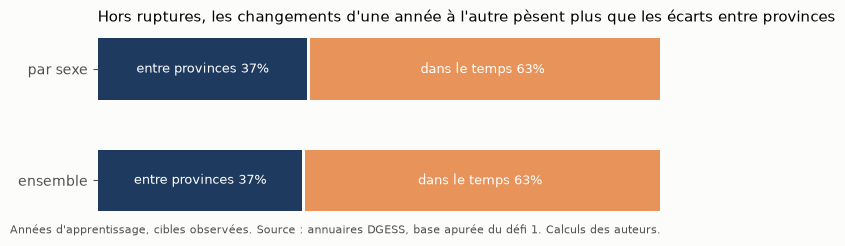

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.4))
for k, (nom, cle) in enumerate([("ensemble", "variance_cible_ensemble"), ("par sexe", "variance_cible_sexe")]):
    v = tables[cle].set_index("mesure")["sans_ruptures"]
    entre = v["part_entre_provinces"]
    ax.barh(k, entre, color="#1f3a5f", height=0.55)
    ax.barh(k, 1 - entre, left=entre + 0.004, color="#e8935a", height=0.55)
    ax.text(entre / 2, k, f"entre provinces {entre:.0%}", color="white", ha="center", va="center", fontsize=9)
    ax.text(entre + (1 - entre) / 2, k, f"dans le temps {1 - entre:.0%}", color="white", ha="center", va="center", fontsize=9)
ax.set_yticks([0, 1], ["ensemble", "par sexe"]); ax.set_xticks([])
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Hors ruptures, les changements d'une année à l'autre pèsent plus que les écarts entre provinces", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Années d'apprentissage, cibles observées. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 3. La décision pour chaque variable

Ordre des règles :

1. **technique** ou **redondante par construction** (identité comptable, seuil d'une autre variable) : retirée ;
2. **trop estimée** : moins de 50 % de valeurs observées ;
3. **colinéaire** : dans un groupe où toutes les paires ont |ρ| ≥ 0,85, on garde la variable la plus observée puis la plus liée à la cible (l'abandon de l'année t est toujours gardé) ;
4. **VIF > 10** : tant qu'une variable est une combinaison linéaire des autres, on retire, parmi celles au-dessus du seuil, la moins liée à la cible ;
5. **lien faible et instable** : |ρ| ≤ 0,10, |ρ sachant l'abandon de t| ≤ 0,10 et même signe moins de 70 % des années ;
6. les autres sont **candidates** (liste des modèles linéaires) ; les modèles d'arbres récupèrent en plus les variables retirées par le seul VIF, nettement liées à la cible (|ρ| ≥ 0,15) et observées à 75 % au moins.

Une variable n'est jamais retirée pour un lien faible seulement : il faut aussi qu'il soit instable.

In [9]:
d = tables["decision_variables_ensemble"]
d["decision"].value_counts()

decision
gardée     35
retirée    34
Name: count, dtype: int64

In [10]:
d[d["decision"] == "retirée"][["variable", "motif", "part_observee"]]

,variable,motif,part_observee
35,tbs_post_primaire_province,"colinéaire avec achevement_primaire_province (ρ = +0.93), gardée car plus observée ou plus liée à la cible ; celle-ci est ensuite retiré...",0.556
36,frequentation_post_primaire_province,"colinéaire avec hors_ecole_16_18_province (ρ = -0.97), gardée car plus observée ou plus liée à la cible",1.000
37,achevement_post_primaire_province,"colinéaire avec achevement_primaire_province (ρ = +0.86), gardée car plus observée ou plus liée à la cible ; celle-ci est ensuite retiré...",0.556
38,hors_ecole_12_15_province,"colinéaire avec hors_ecole_16_18_province (ρ = +0.99), gardée car plus observée ou plus liée à la cible",1.000
39,hors_ecole_6_11_province,"colinéaire avec hors_ecole_16_18_province (ρ = +0.98), gardée car plus observée ou plus liée à la cible",1.000
40,tba_6e_province,"colinéaire avec achevement_primaire_province (ρ = +0.95), gardée car plus observée ou plus liée à la cible ; celle-ci est ensuite retiré...",0.556
41,alphabetisation_adultes_province,"colinéaire avec hors_ecole_16_18_province (ρ = -0.89), gardée car plus observée ou plus liée à la cible",1.000
42,filles_17_ans_mariees_province,"VIF = 11.8 > 10 : combinaison linéaire des autres variables, la moins liée à la cible parmi celles au-dessus du seuil",1.000
43,frequentation_secondaire_province,"colinéaire avec hors_ecole_16_18_province (ρ = -0.90), gardée car plus observée ou plus liée à la cible",1.000
44,rapport_cm2_cp1,"colinéaire avec part_cp1 (ρ = -0.95), gardée car plus observée ou plus liée à la cible",0.995


In [11]:
tables["variables_modele_ensemble"]

,variable,liste_lineaire,liste_arbres,rho_global,part_observee
0,abandons_primaire_orpaillage_pour_1000_region,True,True,0.5357,0.778
1,hors_ecole_16_18_province,True,True,0.5122,1.000
2,abandon_primaire_precedent,True,True,0.4467,0.884
3,part_cp1,True,True,0.4373,0.998
4,ratio_eleves_classe_post_primaire_region,True,True,-0.4041,0.556
5,abandons_primaire_mariage_grossesse_pour_1000_region,True,True,0.3699,0.778
6,part_eleves_primaire_12_ans_et_plus,True,True,-0.3471,0.887
7,parite_scolarisation_primaire_province,True,True,-0.3346,1.000
8,parite_scolarisation_secondaire_province,True,True,-0.2891,1.000
9,redoublement_primaire_precedent,True,True,-0.2731,0.884


## 4. Les colinéarités

Groupes de variables dont toutes les paires ont une corrélation de rang d'au moins 0,85 en valeur absolue.

In [12]:
tables["groupes_colineaires_ensemble"].groupby("groupe")["variable"].apply(", ".join).to_frame("variables")

,variables
groupe,
4,"eleves_par_maitre_primaire, eleves_par_salle_primaire"
9,"emploi_15_24_province, travail_enfants_7_14_province"
41,"tba_primaire_province, tbs_primaire_province, tns_primaire_province"
43,"alphabetisation_adultes_province, frequentation_post_primaire_province, frequentation_secondaire_province, hors_ecole_12_15_province, ho..."
44,"achevement_post_primaire_province, achevement_primaire_province, tba_6e_province, tbs_post_primaire_province"
46,"part_cp1, rapport_cm2_cp1"


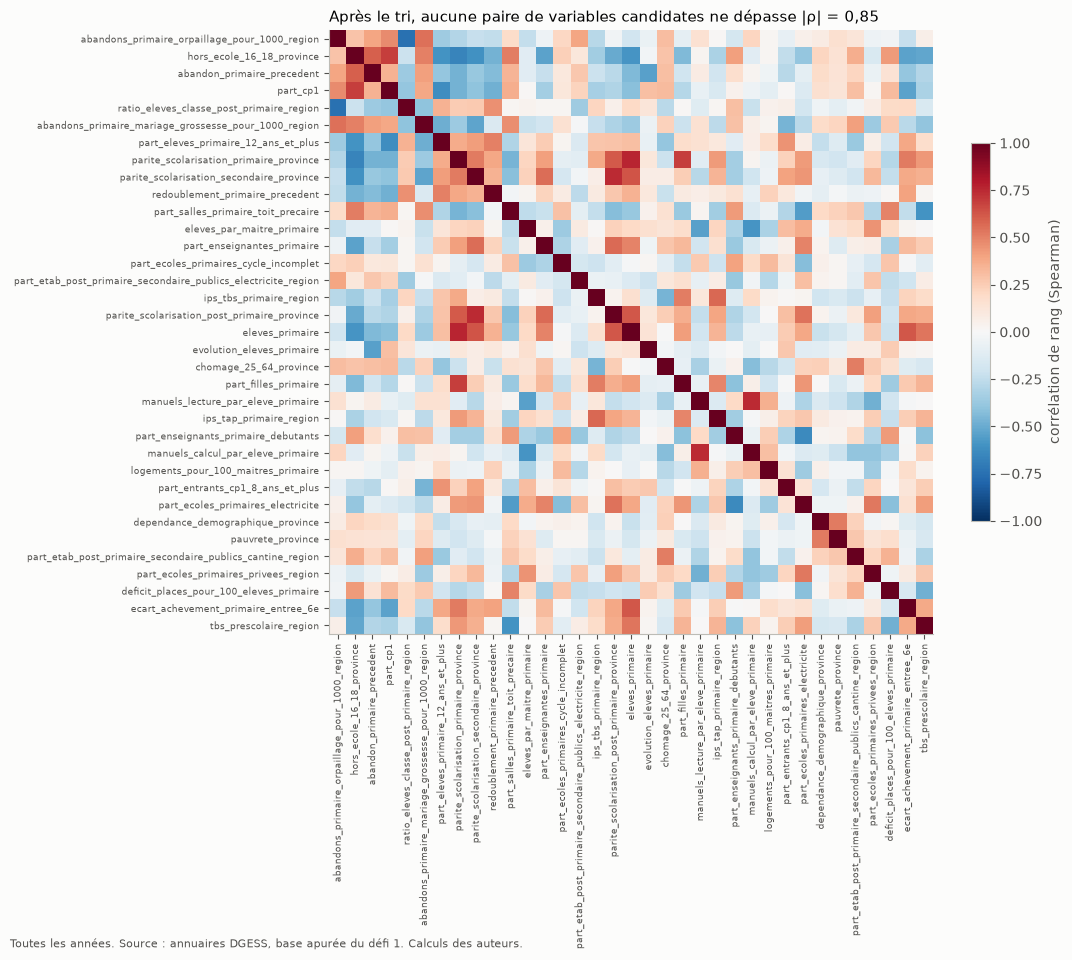

In [13]:
gardees = d.loc[d["decision"] == "gardée", "variable"].tolist()
rho = tables["correlations_ensemble"].set_index("variable").loc[gardees, gardees]
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(gardees)), gardees, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(gardees)), gardees, fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.6, label="corrélation de rang (Spearman)")
ax.set_title("Après le tri, aucune paire de variables candidates ne dépasse |ρ| = 0,85", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Toutes les années. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 5. Le lien des variables candidates avec la cible

- **entre provinces** : la variable explique-t-elle pourquoi certaines provinces décrochent toujours plus ? (corrélation des moyennes par province) ;
- **dans le temps** : explique-t-elle les changements d'une province d'une année à l'autre ? (corrélation des écarts à la moyenne de la province ; vide pour une variable constante, comme le recensement) ;
- **sachant l'abandon de t** : apporte-t-elle une information au-delà de la persistance ?

In [14]:
colonnes = ["variable", "rho_global", "rho_entre_provinces", "rho_dans_le_temps", "rho_partiel_sachant_abandon_t",
            "information_mutuelle", "annees_meme_signe", "part_observee", "vif_final"]
d[d["decision"] == "gardée"][colonnes].reset_index(drop=True)

,variable,rho_global,rho_entre_provinces,rho_dans_le_temps,rho_partiel_sachant_abandon_t,information_mutuelle,annees_meme_signe,part_observee,vif_final
0,abandons_primaire_orpaillage_pour_1000_region,0.5357,0.4619,0.3946,0.3584,0.1785,1.0000,0.778,5.27
1,hors_ecole_16_18_province,0.5122,0.7498,NaN,0.3520,0.1896,1.0000,1.000,6.75
2,abandon_primaire_precedent,0.4467,0.7406,0.1542,NaN,0.1997,1.0000,0.884,2.63
3,part_cp1,0.4373,0.7881,-0.0688,0.2813,0.1048,1.0000,0.998,4.91
4,ratio_eleves_classe_post_primaire_region,-0.4041,-0.2607,-0.3402,-0.2478,0.0969,1.0000,0.556,5.08
5,abandons_primaire_mariage_grossesse_pour_1000_region,0.3699,0.5750,0.2152,0.1921,0.1439,0.8571,0.778,3.62
6,part_eleves_primaire_12_ans_et_plus,-0.3471,-0.5982,-0.0434,-0.2003,0.0968,1.0000,0.887,2.84
7,parite_scolarisation_primaire_province,-0.3346,-0.4111,NaN,-0.1995,0.1487,1.0000,1.000,4.90
8,parite_scolarisation_secondaire_province,-0.2891,-0.4253,NaN,-0.1661,0.1623,1.0000,1.000,5.03
9,redoublement_primaire_precedent,-0.2731,-0.4287,-0.1646,-0.1203,0.1064,1.0000,0.884,2.65


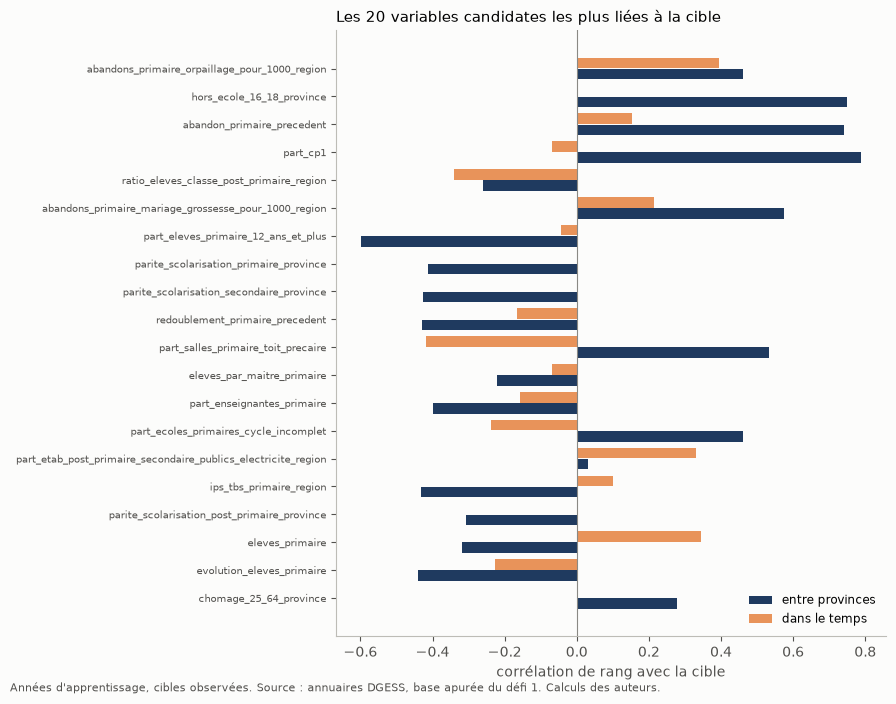

In [15]:
g = d[d["decision"] == "gardée"].copy()
g = g.reindex(g["rho_global"].abs().sort_values().index).tail(20)
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(g))
ax.barh(y - 0.2, g["rho_entre_provinces"], height=0.38, color="#1f3a5f", label="entre provinces")
ax.barh(y + 0.2, g["rho_dans_le_temps"].fillna(0), height=0.38, color="#e8935a", label="dans le temps")
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set_yticks(y, g["variable"], fontsize=7.5)
ax.set_xlabel("corrélation de rang avec la cible")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
ax.set_title("Les 20 variables candidates les plus liées à la cible", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Années d'apprentissage, cibles observées. " + SOURCE, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 6. Par sexe

Mêmes règles sur la base par sexe. La variable `fille` (1 pour les filles) entre comme candidate ; les variables du post-primaire et du secondaire par sexe sont trop estimées pour servir de variables explicatives du primaire (elles seront les cibles des modèles du post-primaire et du secondaire).

In [16]:
ds = tables["decision_variables_sexe"]
ds["decision"].value_counts()

decision
gardée     37
retirée    37
Name: count, dtype: int64

In [17]:
ds[ds["decision"] == "retirée"][["variable", "motif", "part_observee"]]

,variable,motif,part_observee
37,tbs_post_primaire_province,"colinéaire avec achevement_primaire_province (ρ = +0.93), gardée car plus observée ou plus liée à la cible ; celle-ci est ensuite retiré...",0.508
38,part_cp1,"colinéaire avec rapport_cm2_cp1 (ρ = -0.94), gardée car plus observée ou plus liée à la cible",0.787
39,tba_6e_province,"colinéaire avec achevement_primaire_province (ρ = +0.95), gardée car plus observée ou plus liée à la cible ; celle-ci est ensuite retiré...",0.508
40,frequentation_post_primaire_province,"colinéaire avec hors_ecole_16_18_province (ρ = -0.97), gardée car plus observée ou plus liée à la cible",1.000
41,promotion_primaire_precedente,redondante par construction : identité comptable : 100 − abandon − redoublement,0.757
42,hors_ecole_12_15_province,"colinéaire avec hors_ecole_16_18_province (ρ = +0.99), gardée car plus observée ou plus liée à la cible",1.000
43,hors_ecole_6_11_province,"colinéaire avec hors_ecole_16_18_province (ρ = +0.98), gardée car plus observée ou plus liée à la cible",1.000
44,achevement_primaire_province,"VIF = 24.2 > 10 : combinaison linéaire des autres variables, la moins liée à la cible parmi celles au-dessus du seuil",0.813
45,alphabetisation_adultes_province,"colinéaire avec hors_ecole_16_18_province (ρ = -0.89), gardée car plus observée ou plus liée à la cible",1.000
46,filles_17_ans_mariees_province,"VIF = 11.1 > 10 : combinaison linéaire des autres variables, la moins liée à la cible parmi celles au-dessus du seuil",1.000


In [18]:
ds[ds["decision"] == "gardée"][colonnes].reset_index(drop=True)

,variable,rho_global,rho_entre_provinces,rho_dans_le_temps,rho_partiel_sachant_abandon_t,information_mutuelle,annees_meme_signe,part_observee,vif_final
0,abandon_primaire_precedent,0.5306,0.7837,0.1666,NaN,0.3242,1.0000,0.757,2.82
1,abandons_primaire_orpaillage_pour_1000_region,0.5264,0.4941,0.4031,0.3329,0.1988,1.0000,0.778,5.56
2,rapport_cm2_cp1,-0.5104,-0.8741,0.1996,-0.2768,0.2016,1.0000,0.787,2.10
3,achevement_post_primaire_province,-0.4982,-0.7076,-0.1365,-0.2408,0.2418,1.0000,0.508,7.19
4,hors_ecole_16_18_province,0.4794,0.6998,NaN,0.2611,0.1337,1.0000,1.000,8.99
5,part_eleves_primaire_12_ans_et_plus,-0.4188,-0.6734,-0.0463,-0.2107,0.1543,1.0000,0.811,2.70
6,ratio_eleves_classe_post_primaire_region,-0.3873,-0.2334,-0.3805,-0.2690,0.1471,1.0000,0.556,5.23
7,abandons_primaire_mariage_grossesse_pour_1000_region,0.3792,0.6075,0.2096,0.1513,0.1909,1.0000,0.778,3.64
8,fille,-0.3063,-0.3250,NaN,-0.1105,0.0730,1.0000,1.000,1.26
9,parite_scolarisation_primaire_province,-0.2879,-0.3821,NaN,-0.1231,0.1547,1.0000,1.000,4.11


## Ce qu'il faut retenir pour la modélisation

- **Les ruptures de scolarisation** (effectifs qui varient de plus de 30 %) font 8 % des cibles mais 73 % de leur variance : elles relèvent d'une alerte à part.
- **Hors ruptures, le risque reste surtout conjoncturel** : environ 63 % de la variance vient des changements d'une année à l'autre, 37 % des écarts entre provinces.
- **La persistance est forte mais imparfaite** : corrélation de rang de 0,45 (ensemble) à 0,53 (par sexe) entre l'abandon de t et celui de t+1. La référence à battre, la moyenne passée de la province, fait 4,7 points d'erreur absolue moyenne.
- **Les variables les plus liées à la cible** : jeunes hors de l'école (recensement), abandons pour l'orpaillage et pour mariage ou grossesse, poids du CP1, retard scolaire, parité filles / garçons, encadrement au post-primaire.
- **35 variables candidates** pour les modèles linéaires et 41 pour les arbres (ensemble), 37 et 42 par sexe ; chaque retrait a son motif dans `decision_variables_*.csv`.
- **Les garçons abandonnent plus que les filles** au primaire, d'environ 2 à 3 points chaque année.